# Case-by-case analysis
This notebook demonstrates how to visualize which model managed to solve which test-case how often.

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
directory = "../data/"

collection = []
for filename in os.listdir(directory):
    if filename.endswith("_results.jsonl"):
        print(filename)
        df = pd.read_json(directory + filename, lines=True)
        df['model'] = filename.replace(".jsonl_results.jsonl", "").replace("samples_", "")
        collection.append(df)

df = pd.concat(collection)

samples_claude-3-5-sonnet-20240620.jsonl_results.jsonl
samples_claude-3-5-sonnet-20241022.jsonl_results.jsonl
samples_claude-3-opus-20240229.jsonl_results.jsonl
samples_codegemma-7b-instruct-fp16.jsonl_results.jsonl
samples_codellama-70b-instruct-q4_0.jsonl_results.jsonl
samples_codellama.jsonl_results.jsonl
samples_command-r-plus-104b-q4_0.jsonl_results.jsonl
samples_deepseek-coder-v2.jsonl_results.jsonl
samples_gemini-1.5-flash-001.jsonl_results.jsonl
samples_gemini-1.5-pro-001.jsonl_results.jsonl
samples_gemini-pro.jsonl_results.jsonl
samples_gpt-3.5-turbo-1106.jsonl_results.jsonl
samples_gpt-4-1106-preview.jsonl_results.jsonl
samples_gpt-4-turbo-2024-04-09.jsonl_results.jsonl
samples_gpt-4o-2024-05-13.jsonl_results.jsonl
samples_gpt-4o-2024-08-06.jsonl_results.jsonl
samples_gpt-4o-mini-2024-07-18.jsonl_results.jsonl
samples_llama3-70b-instruct-q4_0.jsonl_results.jsonl
samples_llama3-70b-instruct-q8_0.jsonl_results.jsonl
samples_llama3-8b-instruct-fp16.jsonl_results.jsonl
samples_me

In [3]:
df.head()

,task_id,completion,full_response,result,passed,model
0,../test_cases/apply_otsu_threshold_and_count_p...,\n# Plan:\n# 1. Import required libraries (cv2...,Here's the completed code with a step-by-step ...,failed: OpenCV(4.9.0) D:\a\opencv-python\openc...,False,claude-3-5-sonnet-20240620
1,../test_cases/binary_closing.ipynb,\n# Plan:\n# 1. Import necessary libraries (nu...,"Here's the completed code with a plan, necessa...",passed,True,claude-3-5-sonnet-20240620
2,../test_cases/binary_skeleton.ipynb,\n# Plan:\n# 1. Import necessary libraries (sk...,Here's the completed code with a step-by-step ...,failed: Input must be a 2D numpy array of bool...,False,claude-3-5-sonnet-20240620
3,../test_cases/bland_altman.ipynb,\n# Plan:\n# 1. Import required libraries (pan...,"Here's the completed code with a plan, necessa...",passed,True,claude-3-5-sonnet-20240620
4,../test_cases/combine_columns_of_tables.ipynb,\n# Plan:\n# 1. Import required library (panda...,Here's the completed code with a step-by-step ...,passed,True,claude-3-5-sonnet-20240620


In [5]:
# Ensure the 'passed' column is boolean for correct processing.
df['passed'] = df['passed'].astype(bool)
df['error_free'] = df['result'] == "failed: "
df["error"] = df["result"].str.contains("failed", na=False) & (df["result"] != "failed: ") & (df["passed"] != True)

# shorten task name
df['task_id'] = [str(t).replace("../test_cases/", "").replace(".ipynb","") for t in df['task_id']]

# Pivot the dataframe to count True 'passed' values for each model-task combination.
pivot_df = df.pivot_table(index='task_id', columns='model', values=['passed', 'error_free', 'error'], aggfunc='mean', fill_value=0)

# Reset the index if 'task_id' needs to be a column instead of an index
#pivot_df.reset_index(inplace=True)

# Apply formatting to display only two digits after the decimal point for all columns after the first (task_id column)
pivot_df = pivot_df.round(2)

pivot_df

error  \
model                                              claude-3-5-sonnet-20240620   
task_id                                                                         
apply_otsu_threshold_and_count_postiive_pixels                            1.0   
binary_closing                                                            0.0   
binary_skeleton                                                           0.2   
bland_altman                                                              0.0   
combine_columns_of_tables                                                 0.0   
convex_hull_measure_area                                                  0.0   
convolve_images                                                           0.1   
count_number_of_touching_neighbors                                        0.0   
count_objects_over_time                                                   0.0   
count_overlapping_regions                                                 0.0   
create_umap                                                               0.0   
crop_quarter_image                                                        0.9   
deconvolve_image                                                          0.7   
detect_edges                                                              1.0   
expand_labels_without_overlap                                             0.0   
extract_surface_measure_area                                              0.0   
fit_circle                                                                0.0   
label_binary_image_and_count_labels                                       0.1   
label_sequentially                                                        0.0   
list_image_files_in_folder                                                0.0   
map_pixel_count_of_labels                                                 0.0   
mask_image                                                                0.4   
maximum_intensity_projection                                              0.2   
mean_squared_error                                                        0.9   
mean_std_column                                                           0.0   
measure_aspect_ratio_of_regions                                           0.0   
measure_intensity_of_labels                                               0.0   
measure_intensity_over_time                                               0.6   
measure_mean_image_intensity                                              0.0   
measure_pixel_count_of_labels                                             0.0   
measure_properties_of_regions                                             0.0   
open_image_read_voxel_size                                                0.0   
open_image_return_dimensions                                              0.0   
open_nifti_image                                                          0.0   
open_zarr                                                                 0.0   
pair_wise_correlation_matrix                                              0.0   
radial_intensity_profile                                                  0.2   
region_growing_segmentation                                               0.1   
remove_labels_on_edges                                                    0.1   
remove_noise_edge_preserving                                              0.3   
remove_small_labels                                                       0.0   
return_hello_world                                                        0.0   
rgb_to_grey_image_transform                                               0.9   
rotate_image_by_90_degrees                                                0.0   
subsample_image                                                           0.0   
subtract_background_tophat                                                0.0   
sum_images                                                                0.7   
sum_intensity_projecti

In [6]:
df.columns

Index(['task_id', 'completion', 'full_response', 'result', 'passed', 'model',
       'error_free', 'error'],
      dtype='object')

0.13.2


C:\Users\rober\AppData\Local\Temp\ipykernel_34084\1637654786.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_passed["average_task_score"] = df_passed.iloc[:,1:-1].mean(axis=1)


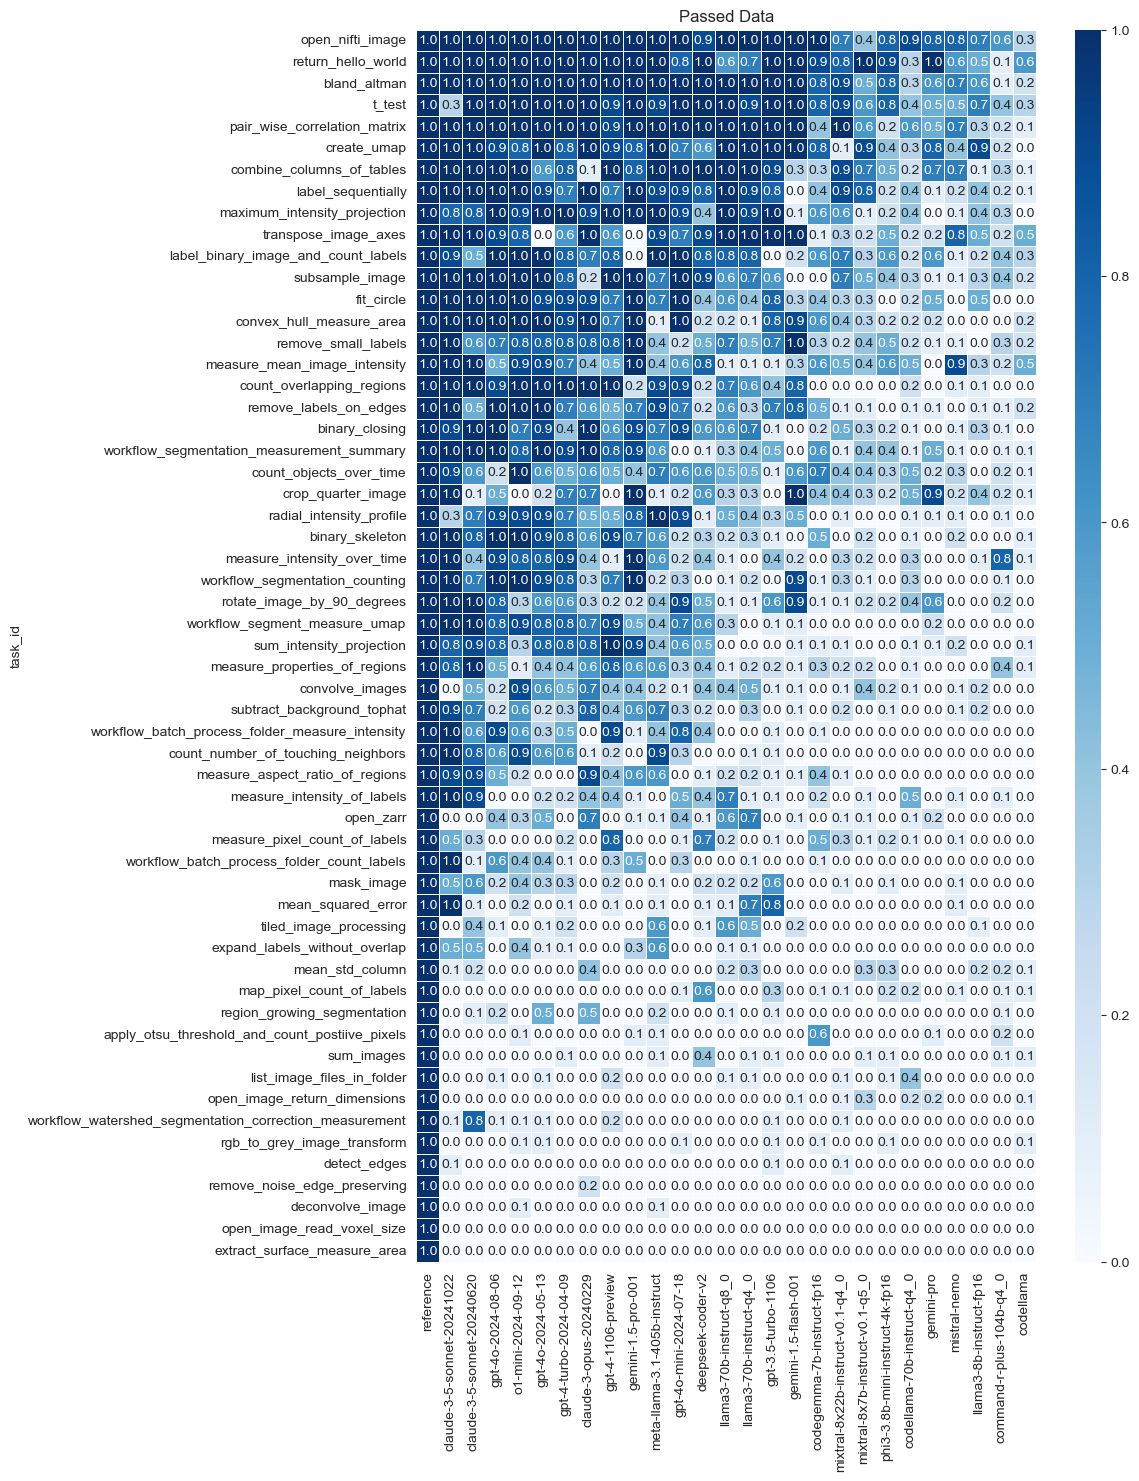

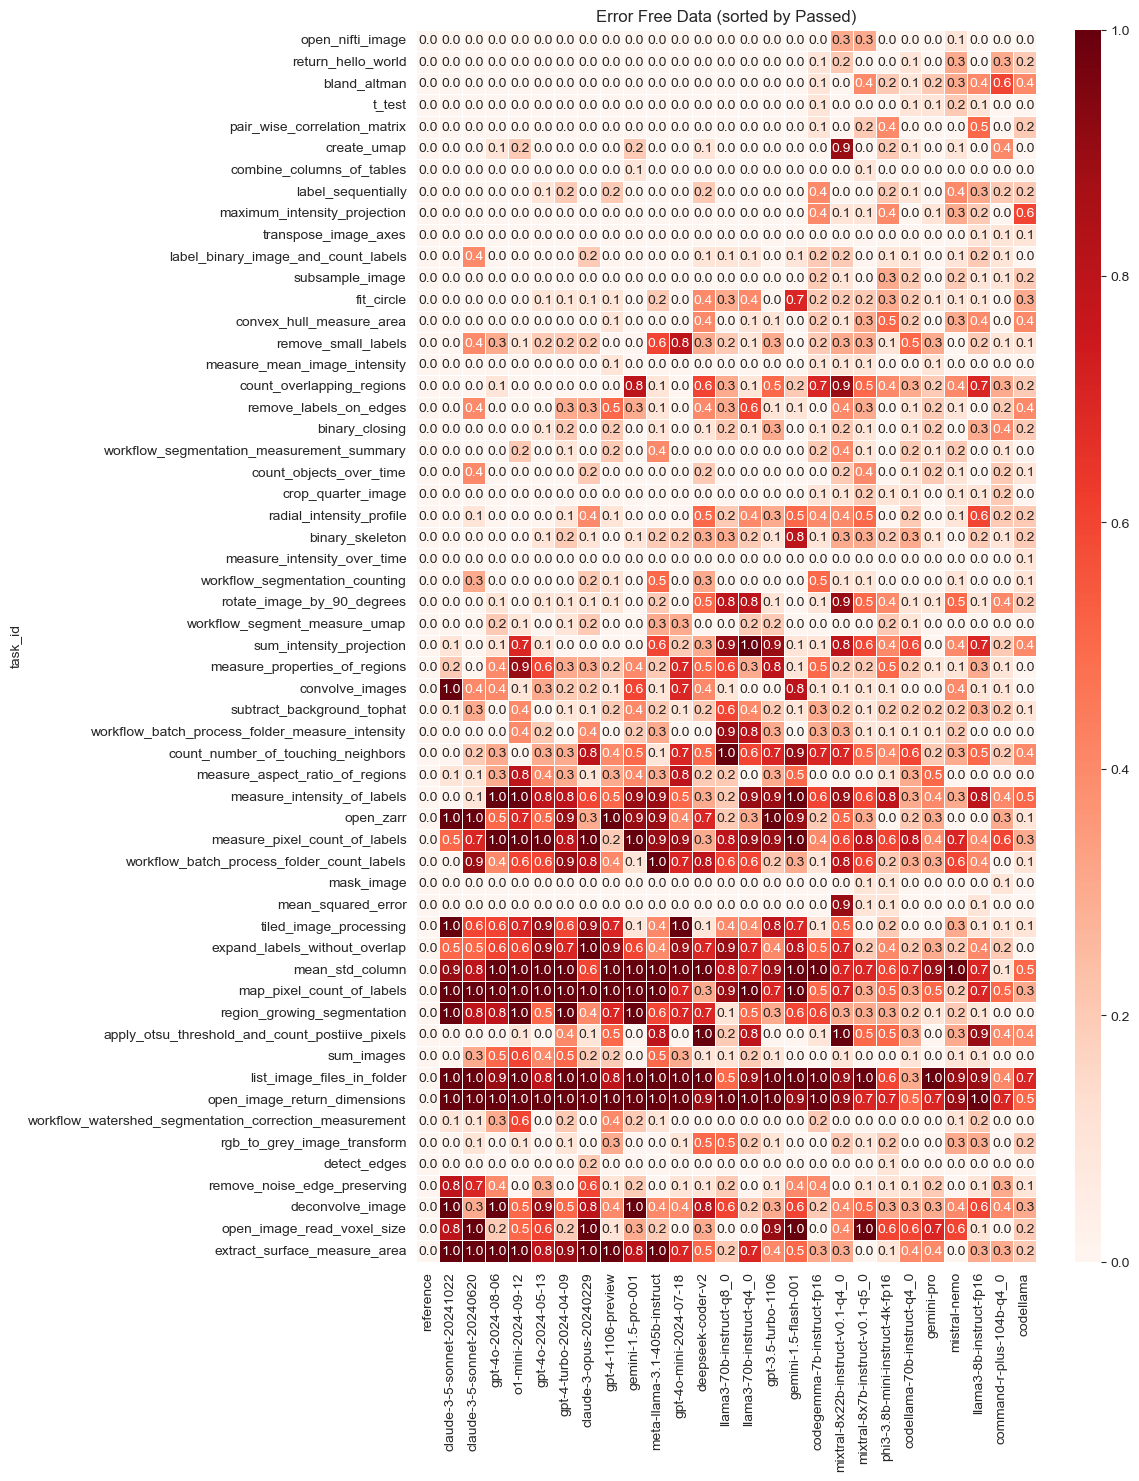

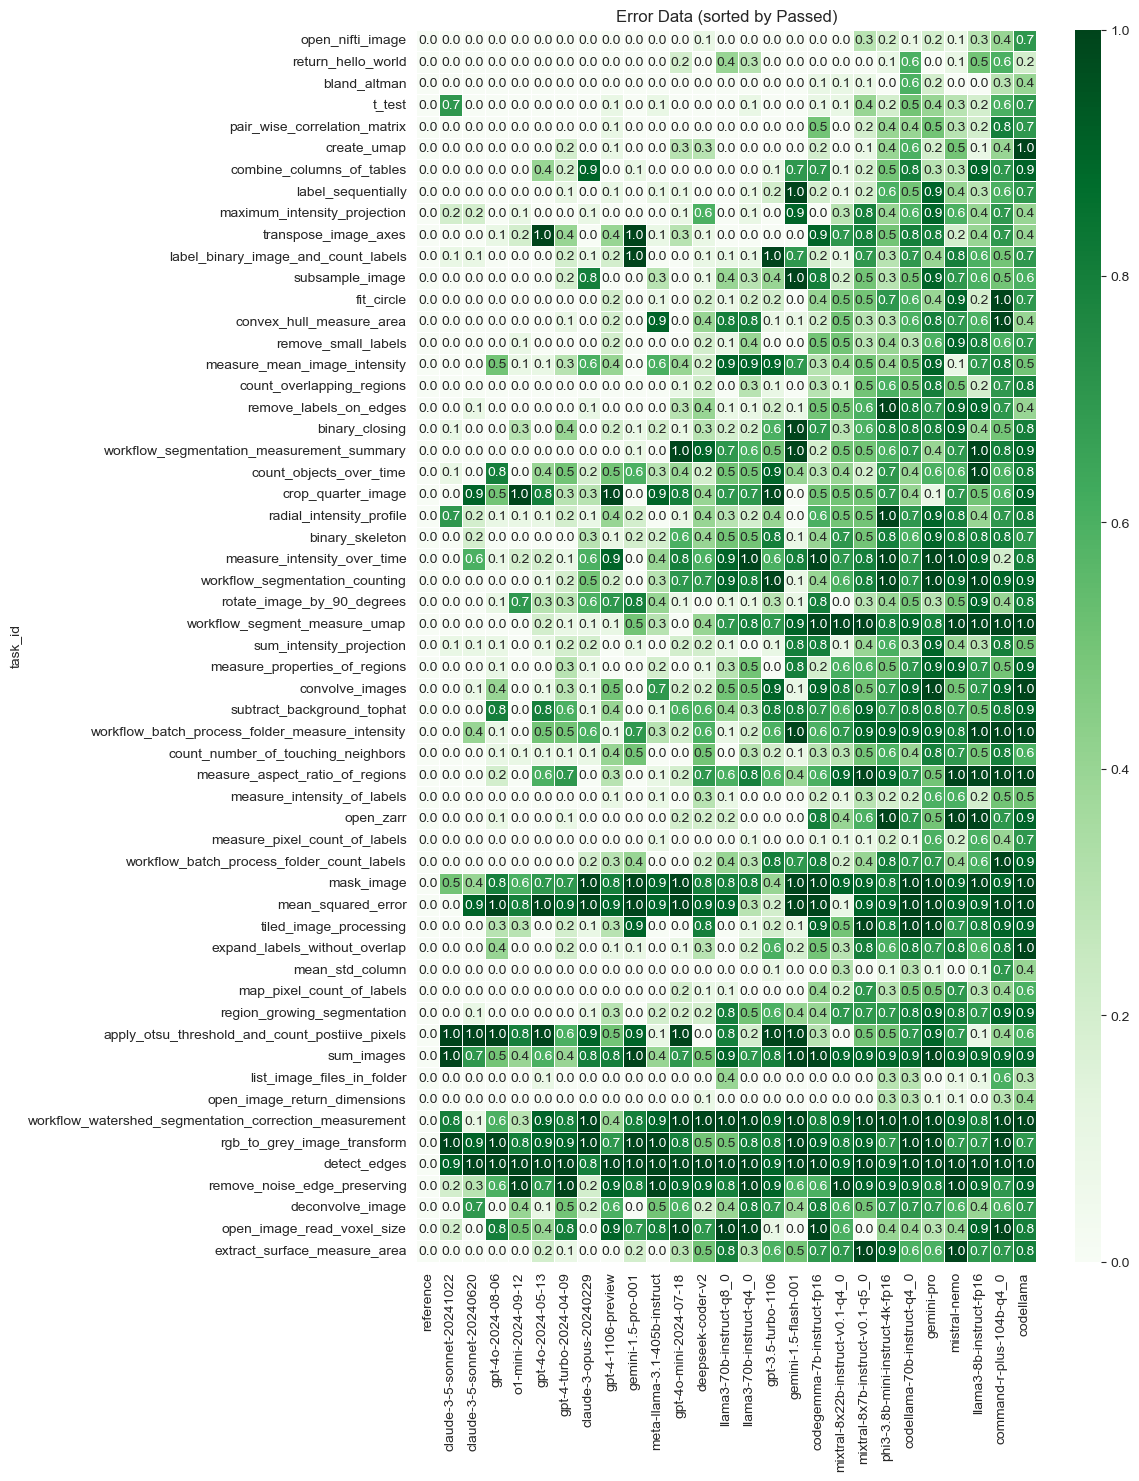

In [8]:
print(sns.__version__)
sns.set_style("white")

df = pivot_df

# Split DataFrame based on MultiIndex columns where first level is "passed" or "error_free"
df_passed = df.xs('passed', level=0, axis=1)
df_error_free = df.xs('error_free', level=0, axis=1)
df_error = df.xs('error', level=0, axis=1)

# Separate the numerical data for plotting based on "passed" data
numerical_data_passed = df_passed.select_dtypes(include=[np.number])
mean_values = numerical_data_passed.mean().sort_values(ascending=False)

# Reorder columns in numerical_data based on sorted mean values from "passed"
numerical_data_passed = numerical_data_passed[mean_values.index]
numerical_data_error_free = df_error_free.select_dtypes(include=[np.number])[mean_values.index]
numerical_data_error = df_error.select_dtypes(include=[np.number])[mean_values.index]

# Calculate average task score and get sorting order based on "passed" data
df_passed["average_task_score"] = df_passed.iloc[:,1:-1].mean(axis=1)
str_column_values = df_passed.sort_values(by="average_task_score", ascending=False).index

# First plot - "passed" data
fig = plt.figure(figsize=(10,16))
numerical_data_passed["average_task_score"] = df_passed.iloc[:,1:-1].mean(axis=1)

sns.heatmap(numerical_data_passed.sort_values("average_task_score",ascending=False).drop(columns=("average_task_score")), 
           annot=True, linewidths=.5, yticklabels=str_column_values, fmt=".1f", 
           cbar_kws={'shrink': 1, 'aspect': 3*16}, cmap="Blues")
plt.gca().set_xlabel('')
plt.title("Passed Data")

plt.savefig("../docs/paper/performance_per_task-exec_passed", bbox_inches="tight", dpi=300)
plt.show()

# Second plot - "error_free" data sorted by "passed" order
fig = plt.figure(figsize=(10,16))

# Sort error_free data by the same order as passed data (both rows and columns)
df_error_free_sorted = numerical_data_error_free.loc[df_passed.sort_values("average_task_score", ascending=False).index]

sns.heatmap(df_error_free_sorted, annot=True, linewidths=.5, yticklabels=str_column_values, 
           fmt=".1f", cbar_kws={'shrink': 1, 'aspect': 3*16}, cmap="Reds")
plt.gca().set_xlabel('')
plt.title("Error Free Data (sorted by Passed)")

plt.savefig("../docs/paper/performance_per_task-exec_error_free", bbox_inches="tight", dpi=300)
plt.show()

# Second plot - "error" data sorted by "passed" order
fig = plt.figure(figsize=(10,16))

# Sort error_ data by the same order as passed data (both rows and columns)
df_error_sorted = numerical_data_error.loc[df_passed.sort_values("average_task_score", ascending=False).index]

sns.heatmap(df_error_sorted, annot=True, linewidths=.5, yticklabels=str_column_values, 
           fmt=".1f", cbar_kws={'shrink': 1, 'aspect': 3*16}, cmap="Greens")
plt.gca().set_xlabel('')
plt.title("Error Data (sorted by Passed)")

plt.savefig("../docs/paper/performance_per_task-exec_error", bbox_inches="tight", dpi=300)
plt.show()